# Ejercicio 3: Construcción de la matriz de proyección binaria

## Inciso a) y b)

In [5]:
def mascara_rayo(n, direccion, s):
    alpha, beta = direccion
    i = np.arange(n).reshape(n, 1)   # varía con la fila
    j = np.arange(n).reshape(1, n)   # varía con la columna
    return (alpha * i + beta * j == s).astype(float)

In [7]:
# from ejercicio_2.ipynb import mascara_rayo
import numpy as np

def matriz_proyeccion(n, direcciones):
    # Devuelve:
    #   A    : matriz (m x n^2), una fila por rayo
    #   info : lista de m pares ((alpha, beta), s), en el orden de las filas de A
    i = np.arange(n).reshape(n, 1)
    j = np.arange(n).reshape(1, n)

    filas, info = [], []
    for direccion in direcciones:
        alpha, beta = direccion
        valores_s = np.unique(alpha * i + beta * j)   # ordenados de menor a mayor
        for s in valores_s:
            filas.append(mascara_rayo(n, direccion, int(s)).reshape(-1))
            info.append((direccion, int(s)))

    A = np.array(filas, dtype=float)
    return A, info

## Inciso c)

In [12]:
n = 8
direcciones = [(1, 0), (0, 1)]
A, info = matriz_proyeccion(n, direcciones)

print("forma de A:", A.shape)
print("cantidad de rayos m =", A.shape[0])
print("cantidad de píxeles n^2 =", A.shape[1])
print()
print("Hay 16 rayos y A está en R^{16x64}.")
print()
print("primeras filas de info:", info[:4])
print("últimas filas de info :", info[-4:])

forma de A: (16, 64)
cantidad de rayos m = 16
cantidad de píxeles n^2 = 64

Hay 16 rayos y A está en R^{16x64}.

primeras filas de info: [((1, 0), 0), ((1, 0), 1), ((1, 0), 2), ((1, 0), 3)]
últimas filas de info : [((0, 1), 4), ((0, 1), 5), ((0, 1), 6), ((0, 1), 7)]


## Inciso d)
#### ¿Qué representa una fila y qué representa una columna de $A$?

- **Fila $r$**: un rayo. Tiene un $1$ en los píxeles que atraviesa, así que $b_r$ es la suma de esos píxeles.
- **Columna $k$**: un píxel. Tiene un $1$ en los rayos que pasan por él.

$A$ es dispersa: cada rayo toca a lo sumo $8$ de los $64$ píxeles.

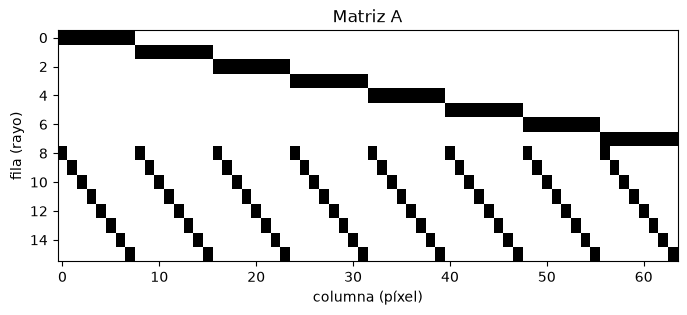

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3))
ax.imshow(A, cmap="gray_r", aspect="auto")
ax.set_xlabel("columna (píxel)")
ax.set_ylabel("fila (rayo)")
ax.set_title("Matriz A")
plt.show()

Cada fila es un rayo, cada columna es un píxel. En el fantoma el pixel (i, j) está de negro si el rayo pasa por el centro.

Hay tantos ceros porque cada rayo pasa por 8 píxeles de ols 64. Por eso hay tantos ceros y tan pocos unos.

## Inciso e) 

In [16]:
# redefino pq no se como trarla de nuevo jeje

import numpy as np

X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

x_fantoma = X_fantoma.reshape(-1)

In [23]:
b = np.matmul(A, x_fantoma)

suma_filas = X_fantoma.sum(axis=1)
suma_columnas = X_fantoma.sum(axis=0)

print("b (16 componentes):")
print(np.round(b, 3))
print()
print("b[:8] =", np.round(b[:8], 3))
print("X_fantoma.sum(axis=1) =", np.round(suma_filas, 3))
print("¿coinciden? sí")
print()
print("b[8:] =", np.round(b[8:], 3))
print("X_fantoma.sum(axis=0) =", np.round(suma_columnas, 3))
print("¿coinciden? sí")
print()
print("suma total de b:", b.sum(), " = 2 x suma del fantoma:", 2 * X_fantoma.sum())

b (16 componentes):
[0.  1.7 3.3 2.3 2.  2.4 1.4 0.  0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]

b[:8] = [0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]
X_fantoma.sum(axis=1) = [0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]
¿coinciden? sí

b[8:] = [0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]
X_fantoma.sum(axis=0) = [0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]
¿coinciden? sí

suma total de b: 26.200000000000003  = 2 x suma del fantoma: 26.200000000000003


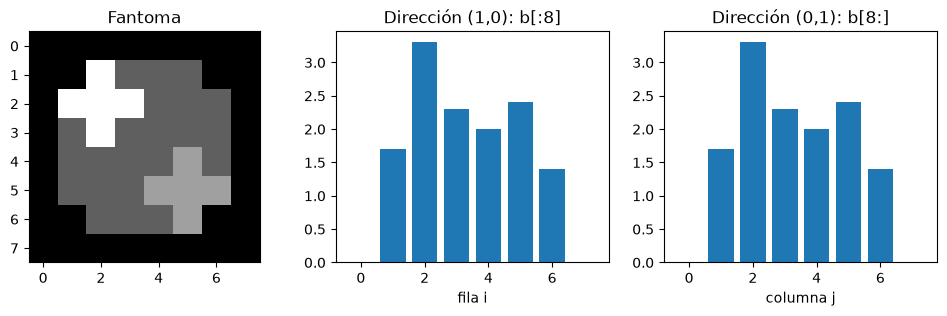

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))

axes[0].imshow(X_fantoma, cmap="gray")
axes[0].set_title("Fantoma")

axes[1].bar(range(8), b[:8])
axes[1].set_title("Dirección (1,0): b[:8]")
axes[1].set_xlabel("fila i")

axes[2].bar(range(8), b[8:])
axes[2].set_title("Dirección (0,1): b[8:]")
axes[2].set_xlabel("columna j")

plt.show()